Flexibility Matrix (D):
[[0.5  0.25]
 [0.25 0.5 ]]

Computed Stiffness Matrix (K = D^-1):
[[ 2.66666667 -1.33333333]
 [-1.33333333  2.66666667]]

Prescribed Displacements (y): [1.  0.5]
Required Forces (f = K_static * y): [2.0000000e+00 4.4408921e-16]
Mass Matrix (M):
[[1. 0.]
 [0. 1.]]

Dynamic Stiffness Matrix (K):
[[ 2. -1.]
 [-1.  2.]]
Eigenvalues (lambda): [1. 3.]
Natural Frequencies (omega rad/s): [1.         1.73205081]

Normal Mode Matrix (Eigenvectors columns):
[[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]
Initial position constraints: [1. 0.]
Computed Mode Participation Coefficients (A): [-0.70710678 -0.70710678]


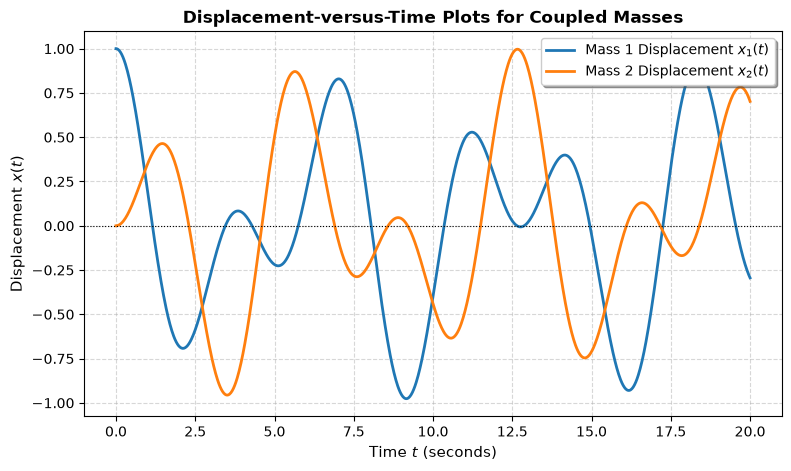

In [1]:
# %% [markdown]
# # Mini-Project 5: Coupled Mechanical Systems and Linear Algebra
# This notebook implements the static and dynamic computational tasks for a coupled 2-mass system,
# verifying analytical properties using numerical linear algebra tools.

# %%
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la

# %% [markdown]
# ## Part 1: Static Stiffness and Flexibility Study
# Based on Lay et al. Section 2.2, Exercises 49-50, we define a flexibility matrix $D$
# and invert it to obtain the structural stiffness matrix $K_{static}$.

# %%
# Define the flexibility matrix D (units: m/N)
D = np.array([
    [0.5, 0.25],
    [0.25, 0.5]
])

print("Flexibility Matrix (D):")
print(D)

# Compute the associated stiffness matrix by inverting D
K_static = la.inv(D)
print("\nComputed Stiffness Matrix (K = D^-1):")
print(K_static)

# Determine the forces required to produce a prescribed displacement: y = [1.0, 0.5]^T
y_prescribed = np.array([1.0, 0.5])
f_required = K_static @ y_prescribed

print("\nPrescribed Displacements (y):", y_prescribed)
print("Required Forces (f = K_static * y):", f_required)

# %% [markdown]
# ## Part 2: Dynamic Coupled Mechanical System Simulation
# We solve the equation of motion $M\mathbf{x}'' + K\mathbf{x} = \mathbf{0}$ for a coupled system 
# using the generalized eigenvalue problem $K\mathbf{v} = \lambda M\mathbf{v}$.

# %%
# Define system parameter configurations (masses m1=m2=1, springs k1=k2=k3=1)
m1, m2 = 1.0, 1.0
k1, k2, k3 = 1.0, 1.0, 1.0

# Construct Mass Matrix (M)
M = np.array([
    [m1, 0.0],
    [0.0, m2]
])

# Construct System Stiffness Matrix (K)
K = np.array([
    [k1 + k2,  -k2],
    [-k2,       k2 + k3]
])

print("Mass Matrix (M):")
print(M)
print("\nDynamic Stiffness Matrix (K):")
print(K)

# %% [markdown]
# ### Solving the Generalized Eigenvalue Problem
# We compute eigenvalues $\lambda_i$ and normal mode vectors $\mathbf{v}_i$.

# %%
# Solve K*v = lambda*M*v using scipy.linalg.eigh (specialized for symmetric matrices)
eigenvalues, eigenvectors = la.eigh(K, M)

# Natural frequencies are the square roots of the eigenvalues
omega = np.sqrt(eigenvalues)

print("Eigenvalues (lambda):", eigenvalues)
print("Natural Frequencies (omega rad/s):", omega)
print("\nNormal Mode Matrix (Eigenvectors columns):")
print(eigenvectors)

# %% [markdown]
# ### Time Integration via Vectorized Modal Superposition
# We project our initial conditions onto the normal mode shapes to solve for the constants 
# $A_i$ assuming the system is released from rest ($\mathbf{x}'(0) = \mathbf{0}$).
# $$\mathbf{x}(t) = A_1 \cos(\omega_1 t)\mathbf{v}_1 + A_2 \cos(\omega_2 t)\mathbf{v}_2$$

# %%
# Define initial displacements: Pull Mass 1 by 1 unit, hold Mass 2 at zero.
x0 = np.array([1.0, 0.0])

# Solve for mode coefficients A: eigenvectors * A = x0 -> A = inv(eigenvectors) * x0
A = la.solve(eigenvectors, x0)

print("Initial position constraints:", x0)
print("Computed Mode Participation Coefficients (A):", A)

# %% [markdown]
# ### Plotting Displacements vs Time

# %%
# Set up a continuous time array for plotting
t = np.linspace(0, 20, 1000)

# Vectorized computation of modal components over all time steps
# A[:, np.newaxis] shapes coefficients to (2, 1)
# omega[:, np.newaxis] * t expands to (2, 1000)
modal_time_history = A[:, np.newaxis] * np.cos(omega[:, np.newaxis] * t)

# Matrix multiplication combining mode shapes (2, 2) with time histories (2, 1000)
# This yields a perfect (2, 1000) results array with zero loops
x_t = eigenvectors @ modal_time_history

x1_t = x_t[0, :]
x2_t = x_t[1, :]

# Create the plot
plt.figure(figsize=(9, 5))
plt.plot(t, x1_t, label=r'Mass 1 Displacement $x_1(t)$', color='#1f77b4', linewidth=2)
plt.plot(t, x2_t, label=r'Mass 2 Displacement $x_2(t)$', color='#ff7f0e', linewidth=2)

plt.title('Displacement-versus-Time Plots for Coupled Masses', fontsize=12, fontweight='bold')
plt.xlabel('Time $t$ (seconds)', fontsize=11)
plt.ylabel('Displacement $x(t)$', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.axhline(0, color='black', linewidth=0.8, linestyle=':')
plt.legend(loc='upper right', frameon=True, shadow=True)
plt.show()
